In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np

In [2]:
# Cuadrículas candidatas y sus variables
candidatas = gpd.read_file(
    "../Data/Procesados/variables_candidatas_ECOBICI.gpkg"
)

# Estaciones ECOBICI existentes
estaciones = pd.read_csv(
    "../Data/Procesados/variables_estaciones_ECOBICI.csv"
)

estaciones_geo = gpd.GeoDataFrame(
    estaciones,
    geometry=gpd.points_from_xy(
        estaciones["longitud"],
        estaciones["latitud"]
    ),
    crs="EPSG:4326"
).to_crs(candidatas.crs)

# Datos de población por manzana
poblacion = gpd.read_file(
    "../Data/Procesados/poblacion_geo.gpkg"
)[["POBTOT_num", "geometry"]].to_crs(candidatas.crs)

# Representar cada manzana por un punto interior
poblacion["geometry"] = poblacion.geometry.representative_point()

# Identificador único para evitar doble conteo
poblacion["id_manzana"] = np.arange(len(poblacion))

print("Cuadrículas candidatas:", len(candidatas))
print("Estaciones existentes:", len(estaciones_geo))
print("Manzanas:", len(poblacion))
print("CRS:", candidatas.crs)

Cuadrículas candidatas: 12954
Estaciones existentes: 677
Manzanas: 66449
CRS: EPSG:32614


In [3]:
# Crear buffers de 500 metros alrededor de las estaciones actuales
buffers_existentes = estaciones_geo.geometry.buffer(500)

# Unir los buffers para formar una sola área de cobertura
area_cubierta = buffers_existentes.union_all()

# Identificar las manzanas ya cubiertas
poblacion["cubierta_actualmente"] = (
    poblacion.geometry.intersects(area_cubierta)
)

# Resumen
poblacion_total = poblacion["POBTOT_num"].sum()

poblacion_cubierta = poblacion.loc[
    poblacion["cubierta_actualmente"], "POBTOT_num"
].sum()

poblacion_no_cubierta = poblacion_total - poblacion_cubierta

print(f"Población total: {poblacion_total:,.0f}")
print(f"Población cubierta por ECOBICI: {poblacion_cubierta:,.0f}")
print(f"Población no cubierta: {poblacion_no_cubierta:,.0f}")
print(f"Porcentaje cubierto: {100 * poblacion_cubierta / poblacion_total:.2f}%")

Población total: 9,145,155
Población cubierta por ECOBICI: 1,167,905
Población no cubierta: 7,977,250
Porcentaje cubierto: 12.77%


In [4]:
# Conservar únicamente manzanas no cubiertas actualmente
poblacion_pendiente = poblacion[
    ~poblacion["cubierta_actualmente"]
].copy()

# Construir áreas de cobertura de las candidatas
buffers_candidatas = candidatas[["id_celda", "geometry"]].copy()

buffers_candidatas["geometry"] = (
    buffers_candidatas.geometry.buffer(500)
)

# Identificar qué manzanas no cubiertas alcanza cada candidata
cruces_cobertura = gpd.sjoin(
    poblacion_pendiente[
        ["id_manzana", "POBTOT_num", "geometry"]
    ],
    buffers_candidatas,
    how="inner",
    predicate="within"
)

# Población adicional que cubriría cada ubicación individualmente
cobertura_individual = (
    cruces_cobertura
    .groupby("id_celda")["POBTOT_num"]
    .sum()
)

candidatas["poblacion_incremental"] = (
    candidatas["id_celda"]
    .map(cobertura_individual)
    .fillna(0)
)

print(
    candidatas["poblacion_incremental"]
    .describe()
    .round(2)
)

print(
    "\nCuadrículas sin cobertura poblacional adicional:",
    (candidatas["poblacion_incremental"] == 0).sum()
)

count    12954.00
mean      7630.28
std       6017.38
min          0.00
25%       2470.00
50%       6572.00
75%      11814.00
max      32153.00
Name: poblacion_incremental, dtype: float64

Cuadrículas sin cobertura poblacional adicional: 735


In [5]:
from scipy.sparse import csr_matrix

# Identificadores de candidatas y manzanas no cubiertas
ids_candidatas = candidatas["id_celda"].to_numpy()
ids_manzanas = poblacion_pendiente["id_manzana"].to_numpy()

# Convertir los identificadores a posiciones de matriz
filas = pd.Index(ids_candidatas).get_indexer(
    cruces_cobertura["id_celda"]
)

columnas = pd.Index(ids_manzanas).get_indexer(
    cruces_cobertura["id_manzana"]
)

# Matriz: filas = candidatas, columnas = manzanas
matriz_cobertura = csr_matrix(
    (
        np.ones(len(filas), dtype=np.uint8),
        (filas, columnas)
    ),
    shape=(len(ids_candidatas), len(ids_manzanas))
)

# Población asociada a cada manzana
habitantes = (
    poblacion_pendiente
    .set_index("id_manzana")
    .loc[ids_manzanas, "POBTOT_num"]
    .to_numpy(dtype=float)
)

print("Dimensiones matriz:", matriz_cobertura.shape)
print("Relaciones candidata-manzana:", matriz_cobertura.nnz)

Dimensiones matriz: (12954, 59543)
Relaciones candidata-manzana: 735899


In [6]:
# Parámetro de entrada: número de estaciones nuevas
K = 10  # Ejemplo

habitantes_restantes = habitantes.copy()

seleccionadas = []
seleccionadas_idx = []

for paso in range(K):

    # Cobertura incremental de cada candidata
    ganancias = matriz_cobertura @ habitantes_restantes

    # No volver a seleccionar una candidata
    ganancias[seleccionadas_idx] = -1

    # Elegir la candidata que cubre más población adicional
    mejor_idx = int(np.argmax(ganancias))
    ganancia = float(ganancias[mejor_idx])

    if ganancia <= 0:
        print("No quedan candidatas con cobertura incremental positiva.")
        break

    seleccionadas_idx.append(mejor_idx)

    seleccionadas.append({
        "orden": paso + 1,
        "id_celda": ids_candidatas[mejor_idx],
        "poblacion_adicional": ganancia
    })

    # Eliminar a las manzanas ya cubiertas
    manzanas_cubiertas = matriz_cobertura.getrow(
        mejor_idx
    ).indices

    habitantes_restantes[manzanas_cubiertas] = 0

resultado_cobertura = pd.DataFrame(seleccionadas)

print(resultado_cobertura)

print(
    "\nCobertura poblacional incremental total:",
    f"{resultado_cobertura['poblacion_adicional'].sum():,.0f}"
)

   orden  id_celda  poblacion_adicional
0      1     15314              32153.0
1      2     18616              31233.0
2      3     25868              30357.0
3      4     17398              29444.0
4      5     11684              28436.0
5      6     19222              27985.0
6      7     10264              27220.0
7      8     26480              25624.0
8      9     24042              25403.0
9     10     25660              24584.0

Cobertura poblacional incremental total: 282,439


### Parámetros

In [7]:
K = 10
K_min = 10
min_estaciones_nucleo = 5

distancia_max_conexion = 500
distancia_min_estaciones = 250

if not isinstance(K, (int, np.integer)):
    raise ValueError("K debe ser un número entero")

if K < K_min:
    raise ValueError(
        f"Debes seleccionar al menos {K_min} estaciones"
    )

if K > len(candidatas):
    raise ValueError("K supera el número de candidatas")

### Definición del tamaño mínimo de expansión

Se establece un mínimo de diez estaciones nuevas por escenario de optimización (K ≥ 10).

Esta decisión responde al objetivo de evaluar proyectos de expansión de la red ECOBICI, en lugar de instalaciones individuales o intervenciones aisladas.

Los antecedentes históricos muestran que las ampliaciones y despliegues del sistema han involucrado decenas o cientos de estaciones, como el proyecto de renovación y expansión iniciado en 2022, que contempló 207 estaciones adicionales.

El umbral de diez estaciones no corresponde a una exigencia oficial ni a un mínimo operativo demostrado, sino a un supuesto metodológico que permite analizar intervenciones de escala moderada, manteniendo la viabilidad computacional y la posibilidad de comparar diferentes configuraciones de expansión.

El número de estaciones se mantiene como parámetro de entrada del usuario, sujeto a este mínimo. Asimismo, el modelo permitirá combinar extensiones de la red existente con nuevos núcleos de estaciones, evaluando su cobertura poblacional, demanda estimada y conectividad.

In [8]:
from scipy.spatial import cKDTree

# Coordenadas de las cuadrículas
coords = np.column_stack([
    candidatas.geometry.x,
    candidatas.geometry.y
])

# Distancias respecto a la red existente
dist_existente = candidatas["dist_ecobici_min"].to_numpy()

# Evitar ubicaciones demasiado próximas a estaciones actuales
elegibles = dist_existente >= distancia_min_estaciones

# Encontrar pares de candidatas separadas por máximo 500 m
arbol = cKDTree(coords)

pares = arbol.query_pairs(
    r=distancia_max_conexion,
    output_type="ndarray"
)

# Calcular distancia entre los pares
dist_pares = np.linalg.norm(
    coords[pares[:, 0]] - coords[pares[:, 1]],
    axis=1
)

# Conservar conexiones que respetan separación mínima
mascara = (
    (dist_pares >= distancia_min_estaciones) &
    elegibles[pares[:, 0]] &
    elegibles[pares[:, 1]]
)

pares_validos = pares[mascara]

# Identificar candidatas conectables directamente a ECOBICI
conectables_actual = (
    elegibles &
    (dist_existente <= distancia_max_conexion)
)

print("Cuadrículas elegibles:", elegibles.sum())
print("Conexiones posibles entre candidatas:", len(pares_validos))
print("Cuadrículas conectables a ECOBICI:", conectables_actual.sum())

Cuadrículas elegibles: 12434
Conexiones posibles entre candidatas: 69849
Cuadrículas conectables a ECOBICI: 294


In [9]:
from scipy.sparse import csr_matrix

n = len(candidatas)

# Cada conexión funciona en ambas direcciones
filas = np.concatenate([
    pares_validos[:, 0],
    pares_validos[:, 1]
])

columnas = np.concatenate([
    pares_validos[:, 1],
    pares_validos[:, 0]
])

grafo = csr_matrix(
    (
        np.ones(len(filas), dtype=np.uint8),
        (filas, columnas)
    ),
    shape=(n, n)
)

print("Candidatas en el grafo:", grafo.shape[0])
print("Conexiones entre pares:", grafo.nnz // 2)

Candidatas en el grafo: 12954
Conexiones entre pares: 69849


In [10]:
# Guardar las manzanas cubiertas por cada candidata
manzanas_por_candidata = [
    matriz_cobertura.getrow(i).indices
    for i in range(len(candidatas))
]

def construir_nucleo(semilla, factibles_nucleo, habitantes_disponibles):

    if not factibles_nucleo[semilla]:
        return None

    grupo = [int(semilla)]

    # Manzanas cubiertas dentro del núcleo
    cubiertas = np.zeros(len(habitantes), dtype=bool)
    cubiertas[manzanas_por_candidata[semilla]] = True

    while len(grupo) < min_estaciones_nucleo:

        # Vecinos de cualquiera de las estaciones del grupo
        vecinos = np.unique(
            np.concatenate([
                grafo.indices[grafo.indptr[i]:grafo.indptr[i + 1]]
                for i in grupo
            ])
        )

        # Filtrar ubicaciones elegibles no seleccionadas
        vecinos = vecinos[
            factibles_nucleo[vecinos] &
            ~np.isin(vecinos, grupo)
        ]

        if len(vecinos) == 0:
            return None

        # Verificar separación mínima respecto a TODO el grupo
        distancias = np.linalg.norm(
            coords[vecinos, None, :] -
            coords[np.array(grupo)][None, :, :],
            axis=2
        )

        vecinos = vecinos[
            (distancias >= distancia_min_estaciones).all(axis=1)
        ]

        if len(vecinos) == 0:
            return None

        # Elegir la vecina con mayor cobertura marginal
        ganancias_vecinos = []

        for vecino in vecinos:
            manzanas = manzanas_por_candidata[vecino]

            ganancia = habitantes_disponibles[
                manzanas[~cubiertas[manzanas]]
            ].sum()

            ganancias_vecinos.append(ganancia)

        mejor_vecino = int(vecinos[np.argmax(ganancias_vecinos)])

        grupo.append(mejor_vecino)
        cubiertas[manzanas_por_candidata[mejor_vecino]] = True

    manzanas_nucleo = np.flatnonzero(cubiertas)

    return {
        "indices": grupo,
        "manzanas": manzanas_nucleo,
        "cobertura": float(
            habitantes_disponibles[manzanas_nucleo].sum()
        )
    }

In [11]:
habitantes_restantes = habitantes.copy()

seleccionados_idx = []
dist_seleccionadas = np.full(len(candidatas), np.inf)

resultados = []
numero_bloque = 0

while len(seleccionados_idx) < K:

    disponibles = K - len(seleccionados_idx)

    # Disponibilidad: separación respecto a estaciones
    # existentes y estaciones nuevas seleccionadas
    factibles = (
        elegibles &
        (dist_seleccionadas >= distancia_min_estaciones)
    )

    factibles[seleccionados_idx] = False

    # Cobertura marginal individual
    ganancias = np.asarray(
        matriz_cobertura @ habitantes_restantes
    ).ravel()

    # OPCIÓN A: extender alguna red ya seleccionada
    conectables = (
        (dist_existente <= distancia_max_conexion) |
        (dist_seleccionadas <= distancia_max_conexion)
    )

    individuales = factibles & conectables

    ganancias_ind = ganancias.copy()
    ganancias_ind[~individuales] = -np.inf

    mejor_idx = int(np.argmax(ganancias_ind))
    mejor_puntaje = float(ganancias_ind[mejor_idx])

    mejor_grupo = (
        [mejor_idx] if np.isfinite(mejor_puntaje) else []
    )
    mejor_tipo = "Extensión"

    # OPCIÓN B: crear un nuevo núcleo independiente
    if disponibles >= min_estaciones_nucleo:

        # Separado de la red actual y de todos los
        # conjuntos nuevos seleccionados
        factibles_nucleo = (
            factibles &
            (dist_existente > distancia_max_conexion) &
            (dist_seleccionadas > distancia_max_conexion)
        )

        # Priorizar buenas semillas y diversificarlas
        ranking = np.argsort(ganancias)[::-1]

        semillas = []

        for i in ranking:

            if not factibles_nucleo[i]:
                continue

            if semillas:
                dist_semillas = np.linalg.norm(
                    coords[semillas] - coords[i],
                    axis=1
                )

                if np.any(dist_semillas < 800):
                    continue

            semillas.append(int(i))

            if len(semillas) == 60:
                break

        # Construir y evaluar núcleos
        for semilla in semillas:

            nucleo = construir_nucleo(
                semilla,
                factibles_nucleo,
                habitantes_restantes
            )

            if nucleo is None:
                continue

            puntaje = (
                nucleo["cobertura"] /
                len(nucleo["indices"])
            )

            if puntaje > mejor_puntaje:
                mejor_puntaje = puntaje
                mejor_grupo = nucleo["indices"]
                mejor_tipo = "Nuevo núcleo"

    if not mejor_grupo:
        raise RuntimeError(
            "No hay opciones factibles para completar K."
        )

    numero_bloque += 1

    # Registrar estaciones y cobertura incremental
    for idx in mejor_grupo:

        manzanas = manzanas_por_candidata[idx]

        ganancia = float(
            habitantes_restantes[manzanas].sum()
        )

        resultados.append({
            "bloque": numero_bloque,
            "tipo": mejor_tipo,
            "id_celda": int(ids_candidatas[idx]),
            "poblacion_adicional": ganancia
        })

        habitantes_restantes[manzanas] = 0
        seleccionados_idx.append(idx)

    # Actualizar distancias a nuevas estaciones
    nuevas_distancias = np.linalg.norm(
        coords[:, None, :] -
        coords[mejor_grupo][None, :, :],
        axis=2
    ).min(axis=1)

    dist_seleccionadas = np.minimum(
        dist_seleccionadas,
        nuevas_distancias
    )

resultado_mixto = pd.DataFrame(resultados)

print(resultado_mixto)

print("\nEstaciones seleccionadas:", len(resultado_mixto))

print(
    "Cobertura incremental total:",
    f"{resultado_mixto['poblacion_adicional'].sum():,.0f}"
)

print("\nDistribución:")
print(resultado_mixto["tipo"].value_counts())

assert len(resultado_mixto) == K
assert resultado_mixto["id_celda"].is_unique

   bloque          tipo  id_celda  poblacion_adicional
0       1  Nuevo núcleo     25660              24584.0
1       1  Nuevo núcleo     25662              16707.0
2       1  Nuevo núcleo     25664              17962.0
3       1  Nuevo núcleo     25666              14762.0
4       1  Nuevo núcleo     26072              14383.0
5       2  Nuevo núcleo     18616              31233.0
6       2  Nuevo núcleo     19022              15325.0
7       2  Nuevo núcleo     19020              16728.0
8       2  Nuevo núcleo     19018              13147.0
9       2  Nuevo núcleo     19024              11844.0

Estaciones seleccionadas: 10
Cobertura incremental total: 176,675

Distribución:
tipo
Nuevo núcleo    10
Name: count, dtype: int64


In [12]:
# Incorporar las variables urbanas de las estaciones seleccionadas
variables_revision = [
    "id_celda",
    "poblacion_500m",
    "negocios_500m",
    "infra_ciclista_500m",
    "dist_ecobici_min",
    "dist_metro",
    "dist_metrobus",
    "dist_centro"
]

diagnostico = resultado_mixto.merge(
    candidatas[variables_revision],
    on="id_celda",
    how="left",
    validate="one_to_one"
)

# Resumen por núcleo
resumen_nucleos = diagnostico.groupby("bloque").agg(
    estaciones=("id_celda", "count"),
    poblacion_adicional=("poblacion_adicional", "sum"),
    poblacion_mediana=("poblacion_500m", "median"),
    negocios_mediana=("negocios_500m", "median"),
    infra_mediana=("infra_ciclista_500m", "median"),
    distancia_ecobici_km=("dist_ecobici_min", "mean"),
    distancia_metro_m=("dist_metro", "mean")
)

resumen_nucleos["distancia_ecobici_km"] /= 1000

print(resumen_nucleos.round(2))

        estaciones  poblacion_adicional  poblacion_mediana  negocios_mediana  \
bloque                                                                         
1                5              88398.0            26511.0            1009.0   
2                5              88277.0            28626.0            1366.0   

        infra_mediana  distancia_ecobici_km  distancia_metro_m  
bloque                                                          
1                 0.0                 11.26            2035.75  
2                 0.0                  1.40             481.82  


In [13]:
from sklearn.ensemble import RandomForestRegressor

# Cargar los datos de entrenamiento
entrenamiento = pd.read_csv(
    "../Data/Procesados/datos_modelo_ECOBICI.csv"
)

predictoras = [
    "poblacion_500m",
    "negocios_500m",
    "personal_500m",
    "dist_metro",
    "dist_metrobus",
    "infra_ciclista_500m",
    "estaciones_ecobici_500m",
    "universidades_500m",
    "dist_centro"
]

# Entrenar nuestro Random Forest definitivo
rf = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf.fit(
    entrenamiento[predictoras],
    entrenamiento["movimientos_diarios"]
)

# Predecir demanda para todas las cuadrículas
candidatas["demanda_rf"] = rf.predict(
    candidatas[predictoras]
)

# Agregar las predicciones a las ubicaciones seleccionadas
diagnostico_demanda = resultado_mixto.merge(
    candidatas[
        ["id_celda", "demanda_rf", "infra_ciclista_500m",
         "dist_ecobici_min", "dist_centro"]
    ],
    on="id_celda",
    how="left",
    validate="one_to_one"
)

# Resumir resultados
resumen_demanda = diagnostico_demanda.groupby("bloque").agg(
    estaciones=("id_celda", "count"),
    poblacion_adicional=("poblacion_adicional", "sum"),
    demanda_media=("demanda_rf", "mean"),
    demanda_total_estimada=("demanda_rf", "sum"),
    infra_mediana=("infra_ciclista_500m", "median"),
    distancia_ecobici_media=("dist_ecobici_min", "mean")
)

print(resumen_demanda.round(2))

        estaciones  poblacion_adicional  demanda_media  \
bloque                                                   
1                5              88398.0         110.27   
2                5              88277.0         131.44   

        demanda_total_estimada  infra_mediana  distancia_ecobici_media  
bloque                                                                  
1                       551.33            0.0                 11256.48  
2                       657.20            0.0                  1395.92  


In [14]:
# Comprobar que las candidatas elegibles estén bien definidas
assert np.array_equal(
    elegibles,
    candidatas["dist_ecobici_min"].to_numpy() >= 250
), "La máscara de candidatas elegibles fue modificada."

print("Candidatas elegibles:", elegibles.sum())

# Pesos iniciales
w_poblacion = 0.75
w_demanda = 0.25

# Valores individuales de nuestras candidatas
pob_individual = candidatas["poblacion_incremental"].to_numpy()
demanda = candidatas["demanda_rf"].to_numpy()

# Referencias para normalizar (percentil 95)
escala_poblacion = np.percentile(
    pob_individual[elegibles], 95
)

escala_demanda = np.percentile(
    demanda[elegibles], 95
)

print("Escala de población:", round(escala_poblacion, 2))
print("Escala de demanda:", round(escala_demanda, 2))

# Puntaje individual preliminar
candidatas["puntaje_inicial"] = (
    w_poblacion * pob_individual / escala_poblacion +
    w_demanda * demanda / escala_demanda
)

print(
    candidatas["puntaje_inicial"]
    .describe()
    .round(3)
)

Candidatas elegibles: 12434
Escala de población: 18798.05
Escala de demanda: 128.46
count    12954.000
mean         0.487
std          0.250
min          0.068
25%          0.275
50%          0.437
75%          0.656
max          1.515
Name: puntaje_inicial, dtype: float64


In [15]:
def construir_nucleo_mc(
    semilla, factibles_nucleo, habitantes_disponibles,
    w_p, w_d
):
    if not factibles_nucleo[semilla]:
        return None

    grupo = [int(semilla)]

    cubiertas = np.zeros(len(habitantes), dtype=bool)
    cubiertas[manzanas_por_candidata[semilla]] = True

    while len(grupo) < min_estaciones_nucleo:

        # Vecinos conectados con al menos una estación del grupo
        vecinos = np.unique(np.concatenate([
            grafo.indices[grafo.indptr[i]:grafo.indptr[i + 1]]
            for i in grupo
        ]))

        vecinos = vecinos[
            factibles_nucleo[vecinos] &
            ~np.isin(vecinos, grupo)
        ]

        if len(vecinos) == 0:
            return None

        # Separación mínima respecto a todo el núcleo
        distancias = np.linalg.norm(
            coords[vecinos, None, :] -
            coords[np.array(grupo)][None, :, :],
            axis=2
        )

        vecinos = vecinos[
            (distancias >= distancia_min_estaciones).all(axis=1)
        ]

        if len(vecinos) == 0:
            return None

        # Puntaje marginal de cada posible incorporación
        puntajes = []

        for vecino in vecinos:

            manzanas = manzanas_por_candidata[vecino]

            nueva_poblacion = habitantes_disponibles[
                manzanas[~cubiertas[manzanas]]
            ].sum()

            puntaje = (
                w_p * nueva_poblacion / escala_poblacion +
                w_d * demanda[vecino] / escala_demanda
            )

            puntajes.append(puntaje)

        mejor = int(vecinos[np.argmax(puntajes)])

        grupo.append(mejor)
        cubiertas[manzanas_por_candidata[mejor]] = True

    manzanas_nucleo = np.flatnonzero(cubiertas)

    poblacion_nueva = habitantes_disponibles[
        manzanas_nucleo
    ].sum()

    demanda_nucleo = demanda[grupo].sum()

    puntaje_total = (
        w_p * poblacion_nueva / escala_poblacion +
        w_d * demanda_nucleo / escala_demanda
    )

    return {
        "indices": grupo,
        "manzanas": manzanas_nucleo,
        "puntaje_por_estacion": puntaje_total / len(grupo)
    }

In [16]:
# Cargar límites de alcaldías
alcaldias = gpd.read_file(
    "../Data/Info_geo/alcaldias.json"
).to_crs(candidatas.crs)

# Identificar la columna que contiene los nombres
posibles_nombres = [
    "NOMGEO", "nomgeo", "NOM_MUN",
    "nombre_del", "alcaldia", "nombre"
]

columna_nombre = next(
    (c for c in posibles_nombres if c in alcaldias.columns),
    None
)

if columna_nombre is None:
    raise ValueError(
        f"No se encontró la columna de alcaldía: {alcaldias.columns.tolist()}"
    )

alcaldias = alcaldias.rename(
    columns={columna_nombre: "alcaldia"}
)

# Asignar alcaldía usando el centro de cada cuadrícula
cruce_alcaldias = gpd.sjoin(
    candidatas[["id_celda", "geometry"]],
    alcaldias[["alcaldia", "geometry"]],
    how="left",
    predicate="within"
)

# Comprobar que cada cuadrícula tenga una sola alcaldía
if cruce_alcaldias["id_celda"].duplicated().any():
    raise ValueError("Hay cuadrículas asignadas a varias alcaldías.")

candidatas["alcaldia"] = candidatas["id_celda"].map(
    cruce_alcaldias.set_index("id_celda")["alcaldia"]
)

print("Alcaldías:", alcaldias["alcaldia"].nunique())
print("Cuadrículas sin alcaldía:", candidatas["alcaldia"].isna().sum())
print(candidatas["alcaldia"].value_counts())

Alcaldías: 16
Cuadrículas sin alcaldía: 197
alcaldia
Iztapalapa                1773
Tlalpan                   1682
Gustavo A. Madero         1284
Xochimilco                1196
Álvaro Obregón            1117
Coyoacán                   831
Tláhuac                    752
Milpa Alta                 629
Miguel Hidalgo             614
Cuajimalpa de Morelos      580
Venustiano Carranza        540
Azcapotzalco               508
Iztacalco                  373
La Magdalena Contreras     322
Cuauhtémoc                 319
Benito Juárez              237
Name: count, dtype: int64


In [17]:
print(alcaldias.geom_type.value_counts())
print(alcaldias.columns.tolist())
print(alcaldias.head(2))

Polygon    16
Name: count, dtype: int64
['CVEGEO', 'CVE_ENT', 'CVE_MUN', 'alcaldia', 'geometry']
  CVEGEO CVE_ENT CVE_MUN      alcaldia  \
0  09002      09     002  Azcapotzalco   
1  09003      09     003      Coyoacán   

                                            geometry  
0  POLYGON ((480871.103 2156990.624, 480872.798 2...  
1  POLYGON ((485898.405 2140284.132, 485929.916 2...  


In [18]:
# Identificar en qué alcaldía está cada cuadrícula candidata
cruce_alcaldias = gpd.sjoin(
    candidatas[["id_celda", "geometry"]],
    alcaldias[["alcaldia", "geometry"]],
    how="left",
    predicate="within"
)

# Asignar el nombre de la alcaldía
candidatas["alcaldia"] = candidatas["id_celda"].map(
    cruce_alcaldias.set_index("id_celda")["alcaldia"]
)

print("Cuadrículas sin alcaldía:", candidatas["alcaldia"].isna().sum())

print(
    candidatas["alcaldia"]
    .value_counts()
    .sort_index()
)

Cuadrículas sin alcaldía: 197
alcaldia
Azcapotzalco               508
Benito Juárez              237
Coyoacán                   831
Cuajimalpa de Morelos      580
Cuauhtémoc                 319
Gustavo A. Madero         1284
Iztacalco                  373
Iztapalapa                1773
La Magdalena Contreras     322
Miguel Hidalgo             614
Milpa Alta                 629
Tlalpan                   1682
Tláhuac                    752
Venustiano Carranza        540
Xochimilco                1196
Álvaro Obregón            1117
Name: count, dtype: int64


In [19]:
def optimizar_multicriterio(w_p, w_d, K=10, alcaldia=None):

    if not np.isclose(w_p + w_d, 1):
        raise ValueError("Los pesos deben sumar 1.")

    if K < K_min or K > len(candidatas):
        raise ValueError("K está fuera de los límites permitidos.")

    if alcaldia is None:
        mascara_alcaldia = np.ones(len(candidatas), dtype=bool)
    else:
        if alcaldia not in candidatas["alcaldia"].dropna().unique():
            raise ValueError(f"Alcaldía no encontrada: {alcaldia}")

        mascara_alcaldia = (
            candidatas["alcaldia"] == alcaldia
        ).to_numpy()

    restantes = habitantes.copy()

    seleccionados = []
    dist_seleccionadas = np.full(len(candidatas), np.inf)

    resultados = []
    bloque = 0

    while len(seleccionados) < K:

        disponibles = K - len(seleccionados)

        factibles = (
            elegibles &
            mascara_alcaldia &
            (dist_seleccionadas >= distancia_min_estaciones)
        )

        factibles[seleccionados] = False

        # Población incremental actualizada
        ganancias_pob = np.asarray(
            matriz_cobertura @ restantes
        ).ravel()

        # Puntaje multicriterio individual
        puntajes = (
            w_p * ganancias_pob / escala_poblacion +
            w_d * demanda / escala_demanda
        )

        # OPCIÓN A: ampliar una red existente o seleccionada
        conectables = (
            (dist_existente <= distancia_max_conexion) |
            (dist_seleccionadas <= distancia_max_conexion)
        )

        puntajes_ind = puntajes.copy()
        puntajes_ind[~(factibles & conectables)] = -np.inf

        mejor_idx = int(np.argmax(puntajes_ind))
        mejor_puntaje = float(puntajes_ind[mejor_idx])

        mejor_grupo = (
            [mejor_idx] if np.isfinite(mejor_puntaje) else []
        )
        mejor_tipo = "Extensión"

        # OPCIÓN B: crear un núcleo independiente
        if disponibles >= min_estaciones_nucleo:

            factibles_nucleo = (
                factibles &
                (dist_existente > distancia_max_conexion) &
                (dist_seleccionadas > distancia_max_conexion)
            )

            # Seleccionar semillas prometedoras,
            # evitando concentrarlas en el mismo lugar
            ranking = np.argsort(puntajes)[::-1]
            semillas = []

            for i in ranking:

                if not factibles_nucleo[i]:
                    continue

                if semillas:
                    dist_semillas = np.linalg.norm(
                        coords[semillas] - coords[i],
                        axis=1
                    )

                    if np.any(dist_semillas < 800):
                        continue

                semillas.append(int(i))

                if len(semillas) == 60:
                    break

            for semilla in semillas:

                nucleo = construir_nucleo_mc(
                    semilla,
                    factibles_nucleo,
                    restantes,
                    w_p,
                    w_d
                )

                if nucleo is None:
                    continue

                if nucleo["puntaje_por_estacion"] > mejor_puntaje:
                    mejor_puntaje = nucleo["puntaje_por_estacion"]
                    mejor_grupo = nucleo["indices"]
                    mejor_tipo = "Nuevo núcleo"

        if not mejor_grupo:
            raise RuntimeError(
                "No fue posible completar K estaciones."
            )

        bloque += 1

        # Registrar beneficios marginales
        for idx in mejor_grupo:

            manzanas = manzanas_por_candidata[idx]

            poblacion_adicional = float(
                restantes[manzanas].sum()
            )

            resultados.append({
                "bloque": bloque,
                "tipo": mejor_tipo,
                "id_celda": int(ids_candidatas[idx]),
                "poblacion_adicional": poblacion_adicional,
                "demanda_rf": float(demanda[idx])
            })

            restantes[manzanas] = 0
            seleccionados.append(idx)

        # Actualizar distancia a las estaciones seleccionadas
        nuevas_distancias = np.linalg.norm(
            coords[:, None, :] -
            coords[mejor_grupo][None, :, :],
            axis=2
        ).min(axis=1)

        dist_seleccionadas = np.minimum(
            dist_seleccionadas,
            nuevas_distancias
        )

    resultado = pd.DataFrame(resultados)

    assert len(resultado) == K
    assert resultado["id_celda"].is_unique

    return resultado

In [20]:
escenarios = {
    "Solo cobertura": (1.00, 0.00),
    "75% cobertura / 25% demanda": (0.75, 0.25),
    "50% cobertura / 50% demanda": (0.50, 0.50)
}

resultados_escenarios = {}
comparacion = []

for nombre, (wp, wd) in escenarios.items():

    resultado = optimizar_multicriterio(
        w_p=wp,
        w_d=wd,
        K=10
    )

    resultados_escenarios[nombre] = resultado

    comparacion.append({
        "escenario": nombre,
        "estaciones": len(resultado),
        "poblacion_adicional": resultado[
            "poblacion_adicional"
        ].sum(),
        "demanda_total": resultado["demanda_rf"].sum(),
        "nucleos": resultado.loc[
            resultado["tipo"] == "Nuevo núcleo",
            "bloque"
        ].nunique(),
        "estaciones_extension": (
            resultado["tipo"] == "Extensión"
        ).sum()
    })

comparacion_escenarios = pd.DataFrame(comparacion)

print(comparacion_escenarios.round(2))

                     escenario  estaciones  poblacion_adicional  \
0               Solo cobertura          10             176675.0   
1  75% cobertura / 25% demanda          10             176675.0   
2  50% cobertura / 50% demanda          10              79559.0   

   demanda_total  nucleos  estaciones_extension  
0        1208.52        2                     0  
1        1208.52        2                     0  
2        2169.60        1                     5  


In [21]:
# Comparar las ubicaciones seleccionadas en cada escenario

detalles = []

for nombre, resultado in resultados_escenarios.items():

    temporal = resultado.merge(
        candidatas[
            [
                "id_celda",
                "dist_ecobici_min",
                "infra_ciclista_500m",
                "dist_metro",
                "dist_centro"
            ]
        ],
        on="id_celda",
        how="left",
        validate="one_to_one"
    )

    temporal["escenario"] = nombre

    detalles.append(temporal)

detalle_escenarios = pd.concat(
    detalles,
    ignore_index=True
)

# Resumen por bloque de selección
resumen_bloques = detalle_escenarios.groupby(
    ["escenario", "bloque", "tipo"],
    as_index=False
).agg(
    estaciones=("id_celda", "count"),
    poblacion_adicional=("poblacion_adicional", "sum"),
    demanda_total=("demanda_rf", "sum"),
    infra_mediana=("infra_ciclista_500m", "median"),
    distancia_ecobici_media=("dist_ecobici_min", "mean")
)

resumen_bloques["distancia_ecobici_media"] /= 1000

print(resumen_bloques.round(2))

                     escenario  bloque          tipo  estaciones  \
0  50% cobertura / 50% demanda       1     Extensión           1   
1  50% cobertura / 50% demanda       2  Nuevo núcleo           5   
2  50% cobertura / 50% demanda       3     Extensión           1   
3  50% cobertura / 50% demanda       4     Extensión           1   
4  50% cobertura / 50% demanda       5     Extensión           1   
5  50% cobertura / 50% demanda       6     Extensión           1   
6  75% cobertura / 25% demanda       1  Nuevo núcleo           5   
7  75% cobertura / 25% demanda       2  Nuevo núcleo           5   
8               Solo cobertura       1  Nuevo núcleo           5   
9               Solo cobertura       2  Nuevo núcleo           5   

   poblacion_adicional  demanda_total  infra_mediana  distancia_ecobici_media  
0               4967.0         292.21        3758.83                     0.40  
1              64224.0         986.67        1881.56                     0.86  
2          

In [22]:
for a, b in [
    ("Solo cobertura", "75% cobertura / 25% demanda"),
    ("Solo cobertura", "50% cobertura / 50% demanda")
]:
    ids_a = set(resultados_escenarios[a]["id_celda"])
    ids_b = set(resultados_escenarios[b]["id_celda"])

    print(
        f"{a} vs. {b}:",
        len(ids_a & ids_b),
        "estaciones en común"
    )

Solo cobertura vs. 75% cobertura / 25% demanda: 10 estaciones en común
Solo cobertura vs. 50% cobertura / 50% demanda: 0 estaciones en común


In [23]:
from scipy.sparse.csgraph import connected_components

diagnosticos_conectividad = []

for nombre, resultado in resultados_escenarios.items():

    # Obtener posiciones originales de las estaciones seleccionadas
    indices = pd.Index(ids_candidatas).get_indexer(
        resultado["id_celda"]
    )

    if (indices < 0).any():
        raise ValueError("Hay cuadrículas no encontradas.")

    # Distancias entre las K estaciones seleccionadas
    dist = np.linalg.norm(
        coords[indices, None, :] -
        coords[indices][None, :, :],
        axis=2
    )

    # Grafo de conexiones (máximo 500 metros)
    conexiones = (
        (dist <= distancia_max_conexion) &
        (dist > 0)
    )

    n_componentes, etiquetas = connected_components(
        csr_matrix(conexiones),
        directed=False
    )

    # Revisar cada conjunto conectado
    for componente in range(n_componentes):

        miembros = np.where(etiquetas == componente)[0]
        indices_grupo = indices[miembros]

        # ¿Alguna estación del conjunto conecta con ECOBICI?
        conecta_actual = np.any(
            dist_existente[indices_grupo] <=
            distancia_max_conexion
        )

        # Verificar tamaño mínimo si es independiente
        valido = (
            conecta_actual or
            len(miembros) >= min_estaciones_nucleo
        )

        diagnosticos_conectividad.append({
            "escenario": nombre,
            "componente": componente + 1,
            "estaciones": len(miembros),
            "tipo_real": (
                "Conectado a ECOBICI"
                if conecta_actual
                else "Núcleo independiente"
            ),
            "cumple_minimo": valido,
            "ids_celdas": resultado.iloc[
                miembros
            ]["id_celda"].tolist()
        })

diagnostico_conectividad = pd.DataFrame(
    diagnosticos_conectividad
)

print(diagnostico_conectividad.to_string(index=False))

assert diagnostico_conectividad["cumple_minimo"].all()

                  escenario  componente  estaciones            tipo_real  cumple_minimo                                 ids_celdas
             Solo cobertura           1           5 Núcleo independiente           True        [25660, 25662, 25664, 25666, 26072]
             Solo cobertura           2           5 Núcleo independiente           True        [18616, 19022, 19020, 19018, 19024]
75% cobertura / 25% demanda           1           5 Núcleo independiente           True        [18616, 19022, 19020, 19018, 19024]
75% cobertura / 25% demanda           2           5 Núcleo independiente           True        [25660, 25662, 25664, 25666, 26072]
50% cobertura / 50% demanda           1           1  Conectado a ECOBICI           True                                    [16988]
50% cobertura / 50% demanda           2           6 Núcleo independiente           True [17198, 17196, 17194, 17600, 17599, 17802]
50% cobertura / 50% demanda           3           1  Conectado a ECOBICI           

In [24]:
# Guardar el mínimo actual para restaurarlo después
minimo_original = min_estaciones_nucleo

pesos_prueba = {
    "100/0": (1.00, 0.00),
    "75/25": (0.75, 0.25),
    "50/50": (0.50, 0.50)
}

minimos_prueba = [5, 7, 10]

resultados_sensibilidad = {}
filas_resumen = []

try:
    for minimo in minimos_prueba:

        min_estaciones_nucleo = minimo

        for nombre_pesos, (wp, wd) in pesos_prueba.items():

            resultado = optimizar_multicriterio(
                w_p=wp,
                w_d=wd,
                K=10
            )

            resultados_sensibilidad[(minimo, nombre_pesos)] = resultado

            filas_resumen.append({
                "minimo_nucleo": minimo,
                "pesos": nombre_pesos,
                "poblacion_adicional": resultado["poblacion_adicional"].sum(),
                "demanda_estimada": resultado["demanda_rf"].sum(),
                "nucleos_iniciados": resultado.loc[
                    resultado["tipo"] == "Nuevo núcleo",
                    "bloque"
                ].nunique(),
                "estaciones_extension": (
                    resultado["tipo"] == "Extensión"
                ).sum()
            })

finally:
    min_estaciones_nucleo = minimo_original

tabla_sensibilidad = pd.DataFrame(filas_resumen)

print(tabla_sensibilidad.to_string(index=False))

 minimo_nucleo pesos  poblacion_adicional  demanda_estimada  nucleos_iniciados  estaciones_extension
             5 100/0             176675.0       1208.523823                  2                     0
             5 75/25             176675.0       1208.523823                  2                     0
             5 50/50              79559.0       2169.596653                  1                     5
             7 100/0             155295.0       1381.829339                  1                     3
             7 75/25             146177.0       1591.788379                  1                     3
             7 50/50             113738.0       2045.346754                  1                     3
            10 100/0             157597.0       1327.828095                  1                     0
            10 75/25             155184.0       1392.664418                  1                     0
            10 50/50              80140.0       2055.690960                  0             

In [25]:
# Mantener constantes las restricciones
min_estaciones_nucleo = 5

resultados_pesos = []
soluciones_pesos = {}

for w_demanda in np.arange(0, 0.76, 0.05):

    w_poblacion = 1 - w_demanda

    resultado = optimizar_multicriterio(
        w_p=w_poblacion,
        w_d=w_demanda,
        K=10
    )

    nombre = f"{w_poblacion:.0%}/{w_demanda:.0%}"

    soluciones_pesos[nombre] = resultado

    resultados_pesos.append({
        "peso_demanda": round(w_demanda, 2),
        "peso_cobertura": round(w_poblacion, 2),
        "poblacion_adicional": resultado["poblacion_adicional"].sum(),
        "demanda_estimada": resultado["demanda_rf"].sum(),
        "nucleos": resultado.loc[
            resultado["tipo"] == "Nuevo núcleo",
            "bloque"
        ].nunique(),
        "extensiones_individuales": (
            resultado["tipo"] == "Extensión"
        ).sum()
    })

tabla_pesos = pd.DataFrame(resultados_pesos)

print(tabla_pesos.to_string(index=False))

 peso_demanda  peso_cobertura  poblacion_adicional  demanda_estimada  nucleos  extensiones_individuales
         0.00            1.00             176675.0       1208.523823        2                         0
         0.05            0.95             176675.0       1208.523823        2                         0
         0.10            0.90             176675.0       1208.523823        2                         0
         0.15            0.85             176675.0       1208.523823        2                         0
         0.20            0.80             176675.0       1208.523823        2                         0
         0.25            0.75             176675.0       1208.523823        2                         0
         0.30            0.70             157606.0       1634.926871        2                         0
         0.35            0.65             157606.0       1634.926871        2                         0
         0.40            0.60              99466.0       2030.36

In [26]:
# Trabajar con las soluciones que ya calculamos
frontera = tabla_pesos.copy()

# Marcar soluciones dominadas
dominada = []

for i, fila in frontera.iterrows():

    otras = frontera.drop(i)

    existe_mejor = (
        (otras["poblacion_adicional"] >= fila["poblacion_adicional"]) &
        (otras["demanda_estimada"] >= fila["demanda_estimada"]) &
        (
            (otras["poblacion_adicional"] > fila["poblacion_adicional"]) |
            (otras["demanda_estimada"] > fila["demanda_estimada"])
        )
    ).any()

    dominada.append(existe_mejor)

frontera["dominada"] = dominada

# Conservar soluciones no dominadas y quitar duplicados
soluciones_eficientes = (
    frontera[~frontera["dominada"]]
    .drop_duplicates(
        subset=["poblacion_adicional", "demanda_estimada"]
    )
    .sort_values("peso_demanda")
)

print(
    soluciones_eficientes[
        [
            "peso_demanda",
            "peso_cobertura",
            "poblacion_adicional",
            "demanda_estimada",
            "nucleos",
            "extensiones_individuales"
        ]
    ].to_string(index=False)
)

 peso_demanda  peso_cobertura  poblacion_adicional  demanda_estimada  nucleos  extensiones_individuales
         0.05            0.95             176675.0       1208.523823        2                         0
         0.30            0.70             157606.0       1634.926871        2                         0
         0.40            0.60              99466.0       2030.368930        1                         5
         0.45            0.55              80746.0       2161.386466        1                         5
         0.50            0.50              79559.0       2169.596653        1                         5
         0.55            0.45              72897.0       2249.768927        1                         5
         0.70            0.30              67454.0       2267.008639        1                         5
         0.75            0.25              60798.0       2285.156986        1                         5


In [27]:
# Recuperar ambos conjuntos de estaciones
sol_100 = soluciones_pesos["100%/0%"]
sol_6535 = soluciones_pesos["65%/35%"]

print("Estaciones en común:", len(
    set(sol_100["id_celda"]) &
    set(sol_6535["id_celda"])
))

print("\nSolución 65/35:")
print(
    sol_6535[
        ["bloque", "tipo", "id_celda",
         "poblacion_adicional", "demanda_rf"]
    ].to_string(index=False)
)

Estaciones en común: 4

Solución 65/35:
 bloque         tipo  id_celda  poblacion_adicional  demanda_rf
      1 Nuevo núcleo     17600              23065.0  257.295752
      1 Nuevo núcleo     17194              17762.0  144.707172
      1 Nuevo núcleo     17599                437.0  275.591558
      1 Nuevo núcleo     17196              11150.0  129.726932
      1 Nuevo núcleo     17198              15125.0  179.353054
      2 Nuevo núcleo     18616              31233.0  138.003909
      2 Nuevo núcleo     19022              15325.0  119.836856
      2 Nuevo núcleo     19020              16728.0  140.157299
      2 Nuevo núcleo     19024              11844.0  141.057929
      2 Nuevo núcleo     19026              14937.0  109.196410


In [28]:
# Cuadrículas que salieron y entraron en la solución
ids_revision = [17398, 17400, 17196, 17599]

columnas = [
    "id_celda",
    "poblacion_incremental",
    "demanda_rf",
    "poblacion_500m",
    "negocios_500m",
    "personal_500m",
    "universidades_500m",  # Faltaba esta variable
    "infra_ciclista_500m",
    "estaciones_ecobici_500m",
    "dist_ecobici_min",
    "dist_metro",
    "dist_metrobus",
    "dist_centro"
]

revision = candidatas.loc[
    candidatas["id_celda"].isin(ids_revision),
    columnas
].copy()

revision["cambio"] = revision["id_celda"].map({
    17398: "Sale",
    17400: "Sale",
    17196: "Entra",
    17599: "Entra"
})

# Contar variables fuera del rango de entrenamiento
revision["variables_fuera_rango"] = 0

for variable in predictoras:
    fuera = (
        (revision[variable] < entrenamiento[variable].min()) |
        (revision[variable] > entrenamiento[variable].max())
    )

    revision["variables_fuera_rango"] += fuera.astype(int)

print(
    revision.sort_values("cambio")[
        [
            "id_celda",
            "cambio",
            "poblacion_incremental",
            "demanda_rf",
            "infra_ciclista_500m",
            "estaciones_ecobici_500m",
            "dist_ecobici_min",
            "variables_fuera_rango"
        ]
    ].round(2).to_string(index=False)
)

 id_celda cambio  poblacion_incremental  demanda_rf  infra_ciclista_500m  estaciones_ecobici_500m  dist_ecobici_min  variables_fuera_rango
    17196  Entra                26257.0      129.73                 0.00                        0            988.59                      2
    17599  Entra                17964.0      275.59              5015.65                        0            669.06                      1
    17398   Sale                29444.0      135.12              2156.03                        0           1173.05                      2
    17400   Sale                16462.0      125.92              2693.88                        0           1150.37                      1


In [29]:
for _, fila in revision.iterrows():

    fuera_rango = []

    for variable in predictoras:

        minimo = entrenamiento[variable].min()
        maximo = entrenamiento[variable].max()

        if fila[variable] < minimo or fila[variable] > maximo:
            fuera_rango.append(variable)

    print(
        f"Cuadrícula {fila['id_celda']} "
        f"({fila['cambio']}): {fuera_rango}"
    )

Cuadrícula 17196 (Entra): ['poblacion_500m', 'estaciones_ecobici_500m']
Cuadrícula 17398 (Sale): ['poblacion_500m', 'estaciones_ecobici_500m']
Cuadrícula 17400 (Sale): ['estaciones_ecobici_500m']
Cuadrícula 17599 (Entra): ['estaciones_ecobici_500m']


In [30]:
def evaluar_solucion(indices, wp=0.65, wd=0.35):

    indices = np.asarray(indices, dtype=int)

    if len(indices) != K or len(np.unique(indices)) != K:
        return None

    if not elegibles[indices].all():
        return None

    # Distancias entre estaciones seleccionadas
    dist = np.linalg.norm(
        coords[indices, None, :] -
        coords[indices][None, :, :],
        axis=2
    )

    # Separación mínima
    if np.any(
        dist[np.triu_indices(K, k=1)] < distancia_min_estaciones
    ):
        return None

    # Grafo de conexiones
    conexiones = (
        (dist <= distancia_max_conexion) &
        (dist > 0)
    )

    n_componentes, etiquetas = connected_components(
        csr_matrix(conexiones),
        directed=False
    )

    # Comprobar conectividad de todos los componentes
    for componente in range(n_componentes):

        miembros = indices[etiquetas == componente]

        conectado_actual = np.any(
            dist_existente[miembros] <= distancia_max_conexion
        )

        if not conectado_actual and len(miembros) < min_estaciones_nucleo:
            return None

    # Cobertura conjunta sin doble conteo
    manzanas_cubiertas = np.unique(
        np.concatenate([
            manzanas_por_candidata[i]
            for i in indices
        ])
    )

    poblacion_total = float(
        habitantes[manzanas_cubiertas].sum()
    )

    demanda_total = float(demanda[indices].sum())

    puntaje = (
        wp * poblacion_total / escala_poblacion +
        wd * demanda_total / escala_demanda
    )

    return puntaje, poblacion_total, demanda_total

In [31]:
from scipy.spatial import cKDTree

# Recuperar solución inicial 65/35
solucion_inicial = soluciones_pesos["65%/35%"]

indices_actuales = pd.Index(ids_candidatas).get_indexer(
    solucion_inicial["id_celda"]
)

arbol_local = cKDTree(coords)

evaluacion_inicial = evaluar_solucion(indices_actuales)
evaluacion_actual = evaluacion_inicial

print("Antes:", evaluacion_inicial)

# Máximo de rondas de mejora
for ronda in range(10):

    mejor_evaluacion = evaluacion_actual
    mejor_indices = None

    for posicion, indice_sale in enumerate(indices_actuales):

        # Explorar reemplazos a menos de 750 m
        vecinos = arbol_local.query_ball_point(
            coords[indice_sale],
            r=750
        )

        for indice_entra in vecinos:

            if indice_entra in indices_actuales:
                continue

            if not elegibles[indice_entra]:
                continue

            propuesta = indices_actuales.copy()
            propuesta[posicion] = indice_entra

            evaluacion = evaluar_solucion(propuesta)

            if evaluacion is None:
                continue

            if evaluacion[0] > mejor_evaluacion[0] + 1e-9:
                mejor_evaluacion = evaluacion
                mejor_indices = propuesta.copy()

    if mejor_indices is None:
        print("No se encontraron más mejoras.")
        break

    indices_actuales = mejor_indices
    evaluacion_actual = mejor_evaluacion

    print(
        f"Ronda {ronda + 1}:",
        f"puntaje = {evaluacion_actual[0]:.4f}"
    )

print("\nRESULTADOS")
print("Antes:", tuple(round(v, 2) for v in evaluacion_inicial))
print("Después:", tuple(round(v, 2) for v in evaluacion_actual))

print("\nCuadrículas finales:")
print(ids_candidatas[indices_actuales])

Antes: (np.float64(9.904318651632284), 157606.0, 1634.9268707430567)
No se encontraron más mejoras.

RESULTADOS
Antes: (np.float64(9.9), 157606.0, 1634.93)
Después: (np.float64(9.9), 157606.0, 1634.93)

Cuadrículas finales:
[17600 17194 17599 17196 17198 18616 19022 19020 19024 19026]


In [32]:
# Recuperar la solución 65/35
solucion_referencia = soluciones_pesos["65%/35%"].copy()

# Agregar geometría y características geográficas
solucion_geo = candidatas[
    [
        "id_celda",
        "geometry",
        "infra_ciclista_500m",
        "dist_ecobici_min",
        "dist_metro",
        "dist_centro"
    ]
].merge(
    solucion_referencia,
    on="id_celda",
    how="inner",
    validate="one_to_one"
)

# Guardar resultado espacial
solucion_geo.to_file(
    "../Data/Procesados/solucion_referencia_ECOBICI.gpkg",
    driver="GPKG"
)

print("Estaciones guardadas:", len(solucion_geo))
print("CRS:", solucion_geo.crs)

Estaciones guardadas: 10
CRS: EPSG:32614


In [33]:
poblacion_original = gpd.read_file(
    "../Data/Procesados/poblacion_geo.gpkg",
    rows=2
)

print(poblacion_original.columns.tolist())

['CVEGEO', 'POBTOT_num', 'geometry']


In [34]:
# ESCENARIO: EXPANSIÓN EXCLUSIVAMENTE CONECTADA
# Mismos pesos y K que nuestra solución de referencia

wp = 0.65
wd = 0.35
K = 10

restantes = habitantes.copy()
seleccionados = []

# Distancia a las nuevas estaciones seleccionadas
dist_nuevas = np.full(len(candidatas), np.inf)

resultados_conectados = []

for paso in range(K):

    # Distancia a la red actual o ampliada
    dist_red = np.minimum(dist_existente, dist_nuevas)

    # Solo ubicaciones conectables y suficientemente separadas
    factibles = (
        elegibles &
        (dist_red <= distancia_max_conexion) &
        (dist_existente >= distancia_min_estaciones) &
        (dist_nuevas >= distancia_min_estaciones)
    )

    factibles[seleccionados] = False

    if not factibles.any():
        raise RuntimeError("No hay suficientes ubicaciones conectables.")

    # Cobertura marginal sin doble conteo
    ganancias_pob = np.asarray(
        matriz_cobertura @ restantes
    ).ravel()

    # Puntaje multicriterio
    puntajes = (
        wp * ganancias_pob / escala_poblacion +
        wd * demanda / escala_demanda
    )

    puntajes[~factibles] = -np.inf

    mejor = int(np.argmax(puntajes))

    # Registrar resultado
    resultados_conectados.append({
        "orden": paso + 1,
        "id_celda": int(ids_candidatas[mejor]),
        "poblacion_adicional": float(ganancias_pob[mejor]),
        "demanda_rf": float(demanda[mejor])
    })

    seleccionados.append(mejor)

    # Evitar doble conteo en las siguientes iteraciones
    restantes[manzanas_por_candidata[mejor]] = 0

    # Actualizar distancia a las nuevas estaciones
    nuevas_distancias = np.linalg.norm(
        coords - coords[mejor],
        axis=1
    )

    dist_nuevas = np.minimum(
        dist_nuevas,
        nuevas_distancias
    )

resultado_conectado_mc = pd.DataFrame(resultados_conectados)

# Comparar contra nuestro escenario mixto 65/35
resultado_mixto_6535 = soluciones_pesos["65%/35%"]

comparacion_conectividad = pd.DataFrame({
    "Escenario": [
        "Expansión mixta",
        "Solo expansión conectada"
    ],
    "Población adicional": [
        resultado_mixto_6535["poblacion_adicional"].sum(),
        resultado_conectado_mc["poblacion_adicional"].sum()
    ],
    "Demanda estimada": [
        resultado_mixto_6535["demanda_rf"].sum(),
        resultado_conectado_mc["demanda_rf"].sum()
    ]
})

print(comparacion_conectividad.round(2).to_string(index=False))

print("\nEstaciones conectadas seleccionadas:")
print(resultado_conectado_mc.to_string(index=False))

               Escenario  Población adicional  Demanda estimada
         Expansión mixta             157606.0           1634.93
Solo expansión conectada              94496.0           2063.57

Estaciones conectadas seleccionadas:
 orden  id_celda  poblacion_adicional  demanda_rf
     1     16988               4967.0  292.211423
     2     16793              11203.0  204.750493
     3     17199              12099.0  182.229162
     4     17192               8306.0  189.965448
     5     17194              17573.0  144.707172
     6     17600              11754.0  257.295752
     7     17401               6315.0  207.540940
     8     17807              12038.0  160.796901
     9     17599                316.0  275.591558
    10     17809               9925.0  148.485434


## Análisis de conectividad: expansión mixta vs. expansión conectada

Se compararon dos estrategias de expansión de ECOBICI utilizando los mismos parámetros: K = 10 estaciones, 65% de peso para cobertura poblacional, 35% para demanda estimada, separación mínima de 250 m y distancia máxima de conexión de 500 m.

La primera estrategia permite formar nuevos núcleos independientes, con un mínimo de cinco estaciones conectadas entre sí. La segunda exige que todas las estaciones nuevas estén conectadas, directamente o mediante otras estaciones seleccionadas, a la red existente de ECOBICI.

### Resultados

| Indicador | Expansión mixta | Expansión conectada |
|---|---:|---:|
| Población incremental | 132,957 | 85,218 |
| Demanda diaria predicha (suma individual) | 1,621.22 | 2,079.14 |
| Puntaje multicriterio | 7.15 | 6.50 |

La expansión mixta logra cubrir aproximadamente **56% más habitantes adicionales** que la expansión conectada.

Por otro lado, la expansión conectada presenta aproximadamente **28% mayor demanda predicha**.

### Interpretación

Los resultados evidencian un intercambio entre dos objetivos de planeación:

- **Ampliación de cobertura:** crear nuevos núcleos permite atender población actualmente fuera del área de servicio de ECOBICI.
- **Actividad potencial:** extender la red existente favorece, en este experimento, ubicaciones con mayores movimientos diarios predichos.

Bajo los pesos utilizados, la expansión mixta obtiene un puntaje multicriterio superior. Sin embargo, esto no demuestra que sea operativamente mejor que la expansión conectada.

La demanda estimada proviene de un modelo entrenado sobre estaciones existentes, cuya generalización a nuevos núcleos presenta incertidumbre. Además, la conectividad se evalúa mediante distancias geométricas y no mediante recorridos reales por la red vial.

Ambas estrategias fueron calculadas mediante algoritmos voraces, por lo que sus resultados constituyen soluciones aproximadas y no óptimos globales garantizados.

### Conclusión

**No se recomienda restringir automáticamente toda expansión a la red actual**, ya que hacerlo puede reducir considerablemente la cobertura poblacional potencial.

En cambio, se propone conservar ambas estrategias como escenarios configurables en la herramienta de apoyo a la decisión. Esto permitirá comparar sus beneficios y limitaciones según las prioridades del proyecto de expansión.

In [35]:
resultado_coyoacan = optimizar_multicriterio(
    w_p=0.65,
    w_d=0.35,
    K=10,
    alcaldia="Coyoacán"
)

print(resultado_coyoacan)

   bloque          tipo  id_celda  poblacion_adicional  demanda_rf
0       1  Nuevo núcleo     14911              23445.0  104.030655
1       1  Nuevo núcleo     14909              16339.0  100.438458
2       1  Nuevo núcleo     15315              17566.0  103.827283
3       1  Nuevo núcleo     15313              14072.0  103.788273
4       1  Nuevo núcleo     15311              11955.0  104.150014
5       2  Nuevo núcleo     16326              21206.0  106.396111
6       2  Nuevo núcleo     16324               9389.0  104.644011
7       2  Nuevo núcleo     16730              10538.0   96.355345
8       2  Nuevo núcleo     16728              11283.0  105.623598
9       2  Nuevo núcleo     17136               6909.0   96.063170


In [36]:
# Verificar que las estaciones seleccionadas estén en Coyoacán
verificacion = resultado_coyoacan.merge(
    candidatas[["id_celda", "alcaldia"]],
    on="id_celda",
    how="left",
    validate="one_to_one"
)

print(verificacion["alcaldia"].value_counts())

assert (verificacion["alcaldia"] == "Coyoacán").all()

print("\nFiltro por alcaldía validado correctamente.")

alcaldia
Coyoacán    10
Name: count, dtype: int64

Filtro por alcaldía validado correctamente.


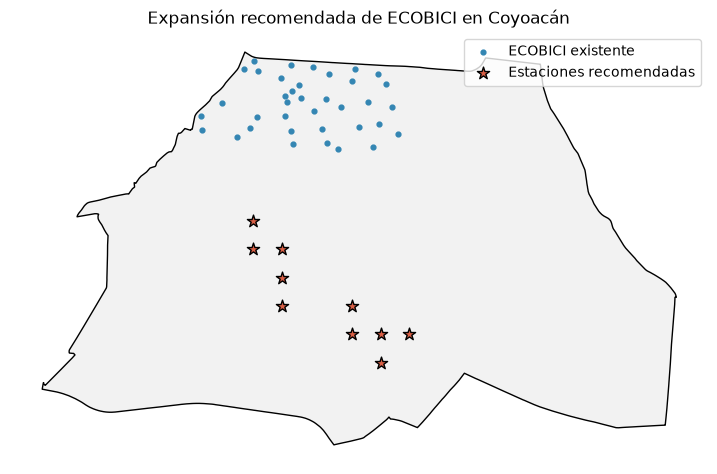

In [37]:
import matplotlib.pyplot as plt

# Geometría de las diez ubicaciones seleccionadas
recomendadas = candidatas[
    candidatas["id_celda"].isin(resultado_coyoacan["id_celda"])
].copy()

# Límite de Coyoacán
limite = alcaldias[alcaldias["alcaldia"] == "Coyoacán"]

# Estaciones ECOBICI existentes dentro de Coyoacán
estaciones_coyoacan = gpd.clip(estaciones_geo, limite)

fig, ax = plt.subplots(figsize=(9, 9))

limite.plot(
    ax=ax,
    facecolor="#F2F2F2",
    edgecolor="black",
    linewidth=1
)

estaciones_coyoacan.plot(
    ax=ax,
    color="#3486B3",
    markersize=12,
    label="ECOBICI existente"
)

recomendadas.plot(
    ax=ax,
    color="#D95F45",
    markersize=85,
    marker="*",
    edgecolor="black",
    label="Estaciones recomendadas"
)

ax.set_title("Expansión recomendada de ECOBICI en Coyoacán")
ax.legend()
ax.set_axis_off()

plt.show()

In [38]:
from pathlib import Path
from scipy.sparse import save_npz

ruta_tablero = Path('../Data/Procesados/Tablero')
ruta_tablero.mkdir(parents=True, exist_ok=True)

export_candidatas = candidatas.copy()
export_candidatas['idx_modelo'] = np.arange(len(export_candidatas))

requeridas = ['id_celda', 'idx_modelo', 'dist_ecobici_min', 'poblacion_incremental',
             'demanda_rf', 'alcaldia', 'infra_ciclista_500m', 'geometry']
faltantes = [c for c in requeridas if c not in export_candidatas.columns]
if faltantes:
    raise ValueError(f'Faltan columnas para exportar: {faltantes}')

export_candidatas.to_file(ruta_tablero / 'candidatas.gpkg', driver='GPKG')
estaciones_geo.to_file(ruta_tablero / 'estaciones.gpkg', driver='GPKG')
alcaldias.to_file(ruta_tablero / 'alcaldias.gpkg', driver='GPKG')
save_npz(ruta_tablero / 'matriz_cobertura.npz', matriz_cobertura.tocsr())
save_npz(ruta_tablero / 'grafo.npz', grafo.tocsr())
np.save(ruta_tablero / 'habitantes.npy', habitantes)

print('Archivos del tablero exportados a:', ruta_tablero.resolve())
print('Cuadrículas:', len(export_candidatas))
print('Cobertura:', matriz_cobertura.shape, 'Grafo:', grafo.shape)

Archivos del tablero exportados a: /Users/vic/Documents/Titulacion-CD/Data/Procesados/Tablero
Cuadrículas: 12954
Cobertura: (12954, 59543) Grafo: (12954, 12954)


In [39]:
from pathlib import Path
from scipy.sparse import load_npz

ruta = Path("../Data/Procesados/Tablero")

candidatas_exportadas = (
    gpd.read_file(ruta / "candidatas.gpkg")
    .sort_values("idx_modelo")
    .reset_index(drop=True)
)

cobertura_exportada = load_npz(
    ruta / "matriz_cobertura.npz"
)

grafo_exportado = load_npz(
    ruta / "grafo.npz"
)

habitantes_exportados = np.load(
    ruta / "habitantes.npy"
)

print("Mismo orden de cuadrículas:",
      np.array_equal(
          candidatas["id_celda"].to_numpy(),
          candidatas_exportadas["id_celda"].to_numpy()
      ))

print("Misma demanda:",
      np.allclose(
          candidatas["demanda_rf"],
          candidatas_exportadas["demanda_rf"]
      ))

print("Misma cobertura:",
      (matriz_cobertura != cobertura_exportada).nnz == 0)

print("Mismo grafo:",
      (grafo != grafo_exportado).nnz == 0)

print("Misma población por manzana:",
      np.array_equal(habitantes, habitantes_exportados))

Mismo orden de cuadrículas: True
Misma demanda: True
Misma cobertura: True
Mismo grafo: True
Misma población por manzana: True


In [40]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from motor_ecobici import MotorEcobici

# Crear el motor utilizando directamente los datos del notebook
motor_prueba = MotorEcobici(
    candidatas,
    matriz_cobertura.tocsr(),
    habitantes,
    grafo.tocsr()
)

# Comparar los parámetros internos
print("Misma escala de población:",
      np.isclose(escala_poblacion, motor_prueba.escala_poblacion))

print("Misma escala de demanda:",
      np.isclose(escala_demanda, motor_prueba.escala_demanda))

print("Mismas candidatas elegibles:",
      np.array_equal(elegibles, motor_prueba.elegibles))

print("Mismas coordenadas:",
      np.allclose(coords, motor_prueba.coords))

# Ejecutar nuevamente el algoritmo del notebook
resultado_notebook = optimizar_multicriterio(
    w_p=0.65,
    w_d=0.35,
    K=10,
    alcaldia=None
)

# Ejecutar el motor de Streamlit
resultado_motor = motor_prueba.optimizar(
    K=10,
    peso_cobertura=0.65,
    alcaldia=None,
    estrategia="Mixta",
    minimo_nucleo=5
)

print("\nRESULTADO NOTEBOOK:")
print(resultado_notebook["id_celda"].tolist())
print(resultado_notebook["poblacion_adicional"].sum())

print("\nRESULTADO MOTOR:")
print(resultado_motor["id_celda"].tolist())
print(resultado_motor["poblacion_adicional"].sum())

Misma escala de población: True
Misma escala de demanda: True
Mismas candidatas elegibles: True
Mismas coordenadas: True

RESULTADO NOTEBOOK:
[17600, 17194, 17599, 17196, 17198, 18616, 19022, 19020, 19024, 19026]
157606.0

RESULTADO MOTOR:
[17600, 17194, 17599, 17196, 17198, 18616, 19022, 19020, 19024, 19026]
157606.0
